# 04 · Evaluation: base vs LoRA fine-tuned Qwen3-4B

**Question:** does the LoRA adapter (`runs/qwen3-4b-lora-r16-v2/best`) extract CUAD clauses better than the same base
model given the same prompt, and did it learn the *skill* (follow a definition) or only the 16 trained categories?

| Input | Where |
|---|---|
| Eval chunks + gold | `data/processed/cuad_v1/eval/{split}_{trained,heldout}.jsonl`, `{split}_gold_contract.jsonl` |
| Predictions | `results/eval/<model>/{split}_{kind}.jsonl`, written by `src/predict.py` (greedy decoding, batch 8) |
| Scoring | `src/eval_metrics.py` (pure functions, unit-tested), `src/eval_report.py` (joins and aggregation) |

The notebook **only reads files**: generation (about 3 h for the test split) runs in the background with
`results/eval/run_predict_test.sh`, which can be re-run to resume. **Test-set discipline:** the prompt, the adapter,
the decoding and the metric code were all fixed before the test predictions were generated. Nothing below was tuned
on test.

In [1]:
import json, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
assert (ROOT / ".venv") in Path(sys.executable).parents, (
    f"Wrong kernel: {sys.executable}. Select 'Python (track-b-slm)' (02_slm_finetuning/.venv).")
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from src import eval_report as er
from src.cuad_data import CLAUSE_CATEGORIES, HEADER_CATEGORIES, HELDOUT_CATEGORIES
from src.eval_metrics import Counts, dedupe, match

SPLIT = "test"                      # "val" to evaluate on validation instead
RUN = ROOT / "runs/qwen3-4b-lora-r16-v2"
NAMES = {"base": "Base (zero-shot)", "ft": "Fine-tuned (LoRA)"}
pd.set_option("display.max_colwidth", 140); pd.set_option("display.precision", 3)
print("split:", SPLIT, "| models:", er.TAGS)

split: test | models: {'base': 'base-qwen3-4b', 'ft': 'qwen3-4b-lora-r16-v2'}


## Step 1 · What was trained

One epoch (1,500 micro-batches, 375 optimizer updates) of LoRA r=16 / α=32 on all linear layers. Validation loss is
computed on a fixed 96-example subset. The `best/` adapter is the checkpoint with the lowest validation loss.

In [2]:
info = json.loads((RUN / "run_info.json").read_text())
val = [json.loads(l) for l in open(RUN / "metrics.jsonl") if '"val"' in l]
print(f"trained {info['started']} → {info['finished']}  ({info['train_seconds']/3600:.1f} h, peak {info['peak_memory_gb']} GB)")
print("best adapter:", info["best"])
pd.DataFrame([{"iteration": int(v["iteration"]), "val_loss": v["val_loss"]} for v in val]).set_index("iteration").T

trained 2026-11-15 00:05:22 → 2026-11-15 04:47:18  (4.7 h, peak 21.44 GB)
best adapter: {'iteration': 1499, 'val_loss': 0.025208953768014908}


iteration,0,249,499,749,999,1249,1499
val_loss,0.638,0.035,0.031,0.03,0.027,0.026,0.025


## Step 2 · Prediction coverage

Each eval chunk is sent twice: once with the **16 trained categories** (`trained`) and once with the **3 held-out
categories** (`heldout`, never requested during training). Both models get the identical prompt, rendered with the
same chat template used in training.

In [3]:
rows = {m: {k: er.load(SPLIT, k, tag) for k in ("trained", "heldout")} for m, tag in er.TAGS.items()}
cov = pd.DataFrame([{"model": m, "set": k, "predicted": sum(r["has_pred"] for r in rs), "chunks": len(rs)}
                    for m, d in rows.items() for k, rs in d.items()])
cov["complete"] = cov.predicted == cov.chunks
display(cov)
if not cov.complete.all():
    print("⚠️  Predictions are still being generated, so the numbers below are PARTIAL. Re-run the notebook when "
          "results/eval/predict_test.log says ALL_DONE.")

,model,set,predicted,chunks,complete
0,base,trained,822,822,True
1,base,heldout,822,822,True
2,ft,trained,822,822,True
3,ft,heldout,822,822,True


## Step 3 · Metrics

| Metric | Definition | Why |
|---|---|---|
| **Span match** | A predicted quote matches a gold quote if the Jaccard similarity of their normalized word sets is **≥ 0.5** (as in the CUAD paper). Matching is one-to-one, and quotes are deduplicated first. | Exact match would penalize harmless boundary differences (a trailing clause or a missing "the"). |
| **P / R / F1** | Micro-averaged over all (chunk or contract) × category items in a group. | Rare categories still count in proportion to their quotes. |
| **Contract level** (headline) | All chunk outputs of a contract are merged and deduplicated, then compared with the contract's gold quotes. | This is what a reviewer receives: one answer per contract. |
| **Chunk level** (diagnostic) | Per chunk; header fields are excluded, and so are categories whose gold span is cut by the chunk boundary. | CUAD offsets point at the first occurrence of a repeated string, so header fields can't be scored per chunk. |
| **False-alarm rate** | Share of items with gold `[]` where the model still returned a quote. | The "confidently wrong" rate. |
| **Miss rate** | Share of items with a gold quote where the model returned `[]`. | Recall at the presence level. |
| **Verbatim rate** | Share of predicted quotes that are exact substrings of the excerpt. | A non-verbatim quote is a hallucination by construction. |
| **Verbatim filter** | Drop non-verbatim quotes before scoring. | The production guardrail; shows how much it helps. |

In [4]:
res = er.evaluate(SPLIT)
n_contracts = len({r["contract"] for r in rows["ft"]["trained"]})
print("contracts with every chunk predicted (scored at contract level):",
      {NAMES[m]: f'{res[m]["trained"]["contract"]["contracts"]}/{n_contracts}' for m in res})

contracts with every chunk predicted (scored at contract level): {'Base (zero-shot)': '80/80', 'Fine-tuned (LoRA)': '80/80'}


## Step 4 · Output health: JSON validity and hallucinated quotes

In [5]:
h = pd.DataFrame([{"model": NAMES[m], "set": k, **res[m][k]["health"]} for m in res for k in ("trained", "heldout")])
cols = ["model", "set", "chunks", "strict_json", "json_ok", "all_keys", "truncated", "quotes", "verbatim_rate",
        "mean_gen_tokens", "s_per_chunk"]
display(h[cols].style.format({c: "{:.1%}" for c in ["strict_json", "json_ok", "all_keys", "truncated", "verbatim_rate"]}
                             | {"mean_gen_tokens": "{:.0f}", "s_per_chunk": "{:.2f}"}).hide(axis="index"))

for m in res:
    bad = [(r["id"], c, q) for r in rows[m]["trained"] if r["has_pred"] for c, qs in r["dropped"].items() for q in qs]
    print(f"\n{NAMES[m]}: {len(bad)} non-verbatim quotes. Examples:")
    for rid, c, q in bad[:4]:
        print(f"  [{c}] {q[:150]!r}")

model,set,chunks,strict_json,json_ok,all_keys,truncated,quotes,verbatim_rate,mean_gen_tokens,s_per_chunk
Base (zero-shot),trained,822,99.5%,99.5%,99.5%,0.0%,2340,89.6%,230,4.57
Base (zero-shot),heldout,822,99.8%,99.8%,99.8%,0.0%,604,84.6%,81,2.75
Fine-tuned (LoRA),trained,822,99.9%,99.9%,99.9%,0.0%,1428,99.3%,159,4.67
Fine-tuned (LoRA),heldout,822,99.9%,99.9%,99.9%,0.0%,228,98.7%,40,2.39



Base (zero-shot): 244 non-verbatim quotes. Examples:
  [Exclusivity] 'Aduro shall be the sole and exclusive owner of, and Consultant hereby assigns to Aduro, any and all writings, documents, work product, inventions, dev'
  [Exclusivity] 'During the Term, neither Nantz Communications nor Nantz shall enter into any activity, employment, independent contract, or other business arrangement'
  [Anti-Assignment] 'Neither Nantz Communications nor Nantz shall assign any of their respective rights or delegate any of their respective duties or obligations under thi'
  [Anti-Assignment] 'The rights granted the Company hereunder shall be used only by it and shall not, without the prior written consent of Nantz Communications or Nantz, b'

Fine-tuned (LoRA): 10 non-verbatim quotes. Examples:
  [Agreement Date] '______ day of ________, 19____'
  [Termination For Convenience] 'Vyera shall have the right to terminate this Agreement in its entirety: (c) at any time following the second (2nd) annivers

## Step 5 · Headline: span F1, base vs fine-tuned

In [6]:
head = pd.DataFrame(er.headline_table(res))
head["Δ F1"] = head.ft_F1 - head.base_F1
display(head[["level", "group", "base_F1", "ft_F1", "Δ F1", "base_P", "base_R", "ft_P", "ft_R",
              "base_false_alarm", "ft_false_alarm"]].style.format(precision=3, na_rep="–").hide(axis="index"))

level,group,base_F1,ft_F1,Δ F1,base_P,base_R,ft_P,ft_R,base_false_alarm,ft_false_alarm
contract,header,0.529,0.832,0.303,0.465,0.613,0.804,0.862,0.273,0.545
contract,clause,0.423,0.738,0.316,0.331,0.585,0.762,0.716,0.279,0.039
contract,heldout,0.274,0.484,0.210,0.178,0.594,0.438,0.541,0.401,0.048
chunk,clause,0.442,0.743,0.301,0.361,0.569,0.782,0.708,0.059,0.008
chunk,heldout,0.291,0.478,0.187,0.195,0.571,0.455,0.502,0.111,0.009


## Step 6 · Per category (contract level)

In [7]:
def per_cat(level="contract", field="contract"):
    out = []
    for kind, cats in (("trained", HEADER_CATEGORIES + CLAUSE_CATEGORIES), ("heldout", HELDOUT_CATEGORIES)):
        for c in cats:
            b, f = (res[m][kind][field]["per_category"].get(c, {}) for m in ("base", "ft"))
            group = "header" if c in HEADER_CATEGORIES else "clause" if c in CLAUSE_CATEGORIES else "held-out"
            out.append({"category": c, "group": group, "gold contracts": f.get("gold_pos"),
                        "base F1": b.get("F1"), "FT F1": f.get("F1"), "FT P": f.get("P"), "FT R": f.get("R"),
                        "FT false alarm": f.get("false_alarm_rate"), "FT miss": f.get("miss_rate")})
    d = pd.DataFrame(out)
    num = [c for c in d.columns if c not in ("category", "group")]
    d[num] = d[num].apply(pd.to_numeric)  # None -> NaN when a model has no predictions yet
    d["Δ F1"] = d["FT F1"] - d["base F1"]
    return d

pc = per_cat()
display(pc.style.format(precision=3, na_rep="–").hide(axis="index"))

category,group,gold contracts,base F1,FT F1,FT P,FT R,FT false alarm,FT miss,Δ F1
Document Name,header,80,0.532,0.897,0.881,0.914,–,0.013,0.365
Parties,header,80,0.606,0.864,0.842,0.886,–,0.025,0.258
Agreement Date,header,69,0.375,0.821,0.765,0.886,0.727,0.058,0.446
Effective Date,header,58,0.263,0.601,0.566,0.642,0.455,0.069,0.338
Expiration Date,clause,64,0.500,0.857,0.934,0.792,0.000,0.141,0.357
Renewal Term,clause,28,0.529,0.800,0.765,0.839,0.019,0.071,0.271
Notice Period To Terminate Renewal,clause,15,0.556,0.848,0.824,0.875,0.031,0.133,0.293
Governing Law,clause,67,0.767,0.958,0.932,0.986,0.077,0.000,0.192
Termination For Convenience,clause,25,0.339,0.772,0.846,0.710,0.018,0.120,0.433
Anti-Assignment,clause,53,0.521,0.768,0.731,0.809,0.222,0.038,0.246


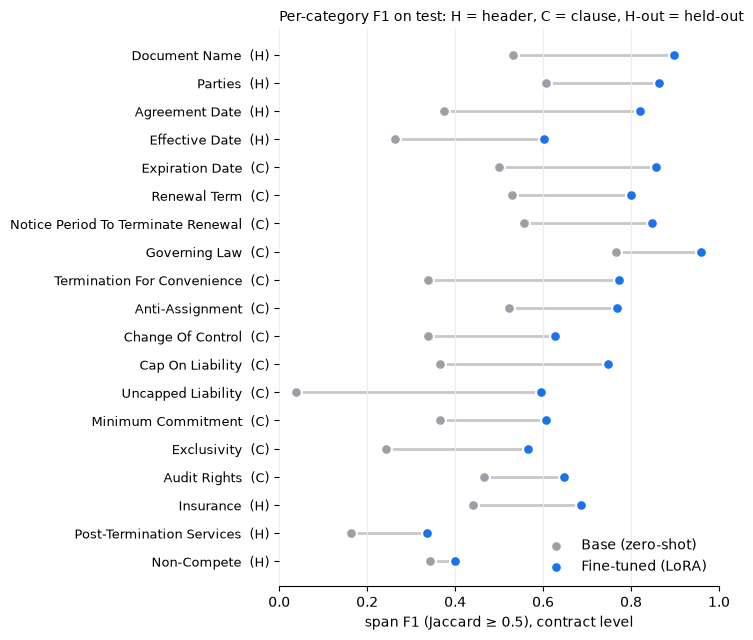

In [8]:
# Dumbbell: base → fine-tuned F1 per category (contract level)
d = pc.iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
for i, r in d.iterrows():
    ax.plot([r["base F1"], r["FT F1"]], [i, i], color="#c8c8c8", lw=2, zorder=1)
ax.scatter(d["base F1"], d.index, s=60, color="#9aa0a6", label=NAMES["base"], zorder=2, edgecolor="white", lw=1.5)
ax.scatter(d["FT F1"], d.index, s=60, color="#1a73e8", label=NAMES["ft"], zorder=3, edgecolor="white", lw=1.5)
ax.set_yticks(d.index, [f"{c}  ({g[0].upper()})" for c, g in zip(d.category, d.group)], fontsize=9)
ax.set_xlim(0, 1); ax.set_xlabel("span F1 (Jaccard ≥ 0.5), contract level")
ax.grid(axis="x", color="#eeeeee"); ax.spines[["top", "right", "left"]].set_visible(False)
ax.legend(loc="lower right", frameon=False)
ax.set_title(f"Per-category F1 on {SPLIT}: H = header, C = clause, H-out = held-out", fontsize=10, loc="left")
plt.tight_layout(); plt.show()

## Step 7 · Chunk level (diagnostic) and the verbatim filter

In [9]:
out = []
for m in res:
    for kind, group in (("trained", "clause"), ("heldout", "heldout")):
        for field, label in (("chunk", "raw"), ("chunk_verbatim", "verbatim-filtered")):
            s = res[m][kind][field]["per_group"][group]
            out.append({"model": NAMES[m], "group": group, "predictions": label, "F1": s["F1"], "P": s["P"],
                        "R": s["R"], "false alarm": s["false_alarm_rate"], "miss": s["miss_rate"],
                        "items": s["items"]})
display(pd.DataFrame(out).style.format(precision=3, na_rep="–").hide(axis="index"))

model,group,predictions,F1,P,R,false alarm,miss,items
Base (zero-shot),clause,raw,0.442,0.361,0.569,0.059,0.183,9849
Base (zero-shot),clause,verbatim-filtered,0.419,0.364,0.494,0.051,0.282,9849
Base (zero-shot),heldout,raw,0.291,0.195,0.571,0.111,0.041,2459
Base (zero-shot),heldout,verbatim-filtered,0.281,0.197,0.488,0.095,0.146,2459
Fine-tuned (LoRA),clause,raw,0.743,0.782,0.708,0.008,0.190,9849
Fine-tuned (LoRA),clause,verbatim-filtered,0.740,0.782,0.702,0.008,0.196,9849
Fine-tuned (LoRA),heldout,raw,0.478,0.455,0.502,0.009,0.374,2459
Fine-tuned (LoRA),heldout,verbatim-filtered,0.472,0.452,0.493,0.009,0.382,2459


## Step 8 · Learned the skill, or memorized the 16 categories?

The 3 held-out categories (Insurance, Post-Termination Services, Non-Compete) were **never requested in training**,
and their definitions were never seen in a training prompt.
* If the fine-tuned model **holds or beats** the base model here, it learned to *follow a definition* and to output
  verbatim quotes and `[]`. That is a transferable skill.
* If it **drops below** the base model, it over-specialized to the trained label set, which is a memorization signal.

The test contracts are also disjoint from the training contracts (contract-level split), so the trained-category
scores above are already on unseen documents.

In [10]:
display(pc[pc.group == "held-out"].style.format(precision=3, na_rep="–").hide(axis="index"))

category,group,gold contracts,base F1,FT F1,FT P,FT R,FT false alarm,FT miss,Δ F1
Insurance,held-out,28,0.440,0.685,0.636,0.742,0.000,0.036,0.245
Post-Termination Services,held-out,24,0.162,0.336,0.271,0.442,0.107,0.125,0.174
Non-Compete,held-out,21,0.343,0.400,0.417,0.385,0.034,0.190,0.057


## Step 9 · Same prompt, base vs fine-tuned (qualitative)

Marks: ✅ matches a gold quote · ❌ no gold match (false positive) · ⚠️ not a verbatim substring of the excerpt ·
**missed** = gold quotes the model did not find. Only categories where gold, base or FT are non-empty are shown.
Examples are picked by rule (see the code), not by hand.

In [11]:
by_id = {m: {k: {r["id"]: r for r in rows[m][k]} for k in rows[m]} for m in rows}

def chunk_f1(r, cats):
    c = Counts()
    for cat in cats:
        if cat not in r["cut"]:
            c.add(r["pred"][cat], r["gold"][cat])
    return c.summary()

def show(rid, kind="trained", excerpt_chars=0):
    g = by_id["ft"][kind][rid]
    lines = [f"### `{rid}`  ({g['type']}, chunk {g['chunk'] + 1}/{g['n_chunks']})"]
    for cat in g["categories"]:
        gold = dedupe(g["gold"][cat])
        preds = {m: by_id[m][kind][rid]["pred"][cat] for m in ("base", "ft")}
        if not (gold or any(preds.values())):
            continue
        cut = " *(cut by chunk boundary, not scored)*" if cat in g["cut"] else ""
        lines.append(f"\n**{cat}**{cut}  \n gold: " + (" · ".join(f"`{q[:160]}`" for q in gold) or "`[]`"))
        for m in ("base", "ft"):
            qs = dedupe(preds[m])
            _, pairs = match(qs, gold)
            hit_p, hit_g = {p for p, _ in pairs}, {x for _, x in pairs}
            marks = [("✅" if q in hit_p else "❌") + ("⚠️" if q not in g["excerpt"] else "") + f" `{q[:160]}`" for q in qs]
            missed = [q for q in gold if q not in hit_g]
            lines.append(f" - {NAMES[m]}: " + (" · ".join(marks) or "`[]`")
                         + (f"  — **missed** {len(missed)}" if missed and qs else ""))
    if excerpt_chars:
        lines.append(f"\n<details><summary>excerpt</summary>\n\n```\n{g['excerpt'][:excerpt_chars]}\n```\n</details>")
    display(Markdown("\n".join(lines)))

both = [rid for rid in by_id["ft"]["trained"]
        if by_id["ft"]["trained"][rid]["has_pred"] and by_id["base"]["trained"][rid]["has_pred"]]
def f1(m, rid, cats=CLAUSE_CATEGORIES): return chunk_f1(by_id[m]["trained"][rid], cats)
def n_gold(rid): r = by_id["ft"]["trained"][rid]; return sum(bool(r["gold"][c]) for c in CLAUSE_CATEGORIES if c not in r["cut"])
def n_pred(m, rid): r = by_id[m]["trained"][rid]; return sum(len(r["pred"][c]) for c in r["categories"])
print(f"{len(both)} chunks predicted by both models")

822 chunks predicted by both models


In [12]:
# Example A: a chunk with ≥ 3 gold clause categories where fine-tuning helped most
cand = [rid for rid in both if n_gold(rid) >= 3]
if cand:
    show(max(cand, key=lambda rid: (f1("ft", rid)["F1"] - f1("base", rid)["F1"], rid)))

### `MPLXLP_06_17_2015-EX-10.1-TRANSPORTATION SERVICES AGREEMENT#2`  (Transportation, chunk 3/13)

**Effective Date**  
 gold: `[]`
 - Base (zero-shot): ❌ `This Agreement is effective June 11, 2015 (the "Effective Date")`
 - Fine-tuned (LoRA): ❌ `This Agreement is effective June 11, 2015 (the "Effective Date").`

**Expiration Date**  
 gold: `The Agreement shall continue through the project's in-service date and for a period of fifteen (15) years after the project's in-service date ("Initial Term").`
 - Base (zero-shot): `[]`
 - Fine-tuned (LoRA): ✅ `The Agreement shall continue through the project's in-service date and for a period of fifteen (15) years after the project's in-service date ("Initial Term").`

**Renewal Term**  
 gold: `This Agreement will automatically renew for up to two (2) renewal terms of five (5) years each (each, an "Extension Period") unless either Party provides the ot`
 - Base (zero-shot): ❌ `This Agreement will automatically renew for up to two (2) renewal terms of five (5) years each (each, an "Extension Period")`  — **missed** 1
 - Fine-tuned (LoRA): ✅ `This Agreement will automatically renew for up to two (2) renewal terms of five (5) years each (each, an "Extension Period") unless either Party provides the ot`

**Notice Period To Terminate Renewal**  
 gold: `This Agreement will automatically renew for up to two (2) renewal terms of five (5) years each (each, an "Extension Period") unless either Party provides the ot`
 - Base (zero-shot): ✅ `unless either Party provides the other Party with written notice of its intent to terminate this Agreement at least six (6) months prior to the end of the Initi`
 - Fine-tuned (LoRA): ✅ `This Agreement will automatically renew for up to two (2) renewal terms of five (5) years each (each, an "Extension Period") unless either Party provides the ot`

**Minimum Commitment**  
 gold: `Shipper guarantees that during each Contract Year, Shipper will meet its Quarterly Volume Commitment or, in the event it fails to do so, shall remit to MPL the `
 - Base (zero-shot): ❌ `Shipper guarantees that during each Contract Year, Shipper will meet its Quarterly Volume Commitment`  — **missed** 1
 - Fine-tuned (LoRA): ✅ `Shipper guarantees that during each Contract Year, Shipper will meet its Quarterly Volume Commitment or, in the event it fails to do so, shall remit to MPL the `

In [13]:
# Example B: a chunk with NO gold quote at all, where the base model returned the most quotes (hallucination pressure)
empty = [rid for rid in both if not any(by_id["ft"]["trained"][rid]["gold"].values())]
if empty:
    rid = max(empty, key=lambda rid: (n_pred("base", rid), rid))
    print(f"base quotes: {n_pred('base', rid)} | FT quotes: {n_pred('ft', rid)}")
    show(rid)

base quotes: 15 | FT quotes: 0


### `VerizonAbsLlc_20200123_8-K_EX-10.4_11952335_EX-10.4_Service Agreement#30`  (Service, chunk 31/61)

**Parties**  
 gold: `[]`
 - Base (zero-shot): ❌ `Wilmington Trust, National Association` · ❌ `U.S. Bank National Association` · ❌ `Cellco` · ❌ `Verizon` · ❌ `the Servicer` · ❌ `the Custodian` · ❌ `the Marketing Agent` · ❌ `the Issuer` · ❌ `the Master Trust` · ❌ `the Originators` · ❌ `the nominee of the Originators` · ❌ `the Cap Counterparty` · ❌ `the Cap Custodian`
 - Fine-tuned (LoRA): `[]`

In [14]:
# Example C: a fine-tuned failure, i.e. the chunk with ≥ 2 gold clause categories and the lowest FT F1
cand = [rid for rid in both if n_gold(rid) >= 2]
if cand:
    show(min(cand, key=lambda rid: (f1("ft", rid)["F1"], rid)))

### `BIOFRONTERAAG_04_29_2019-EX-4.17-SUPPLY AGREEMENT#4`  (Supply, chunk 5/14)

**Parties**  
 gold: `[]`
 - Base (zero-shot): ❌ `the Parties`
 - Fine-tuned (LoRA): `[]`

**Effective Date**  
 gold: `[]`
 - Base (zero-shot): ❌ `This Agreement comes into force as of the Effective Date`
 - Fine-tuned (LoRA): `[]`

**Expiration Date**  
 gold: `This Agreement comes into force as of the Effective Date and shall remain valid during the term of the LSA.`
 - Base (zero-shot): `[]`
 - Fine-tuned (LoRA): `[]`

**Termination For Convenience**  
 gold: `[]`
 - Base (zero-shot): ❌ `This Agreement may be terminated at any time upon the occurrence of any of the following events: 4.2.1 The failure of either party to comply with its obligation`
 - Fine-tuned (LoRA): `[]`

**Anti-Assignment**  
 gold: `[]`
 - Base (zero-shot): ❌ `Either party may terminate this Agreement immediately by giving the other party written notice thereof in the event such other party in the event of (a) a volun`
 - Fine-tuned (LoRA): `[]`

**Audit Rights**  
 gold: `Supplier shall use its commercially reasonable efforts to permit CUTANEA to have access to Supplier's (and its agents' and subcontractors') facilities upon reas`
 - Base (zero-shot): `[]`
 - Fine-tuned (LoRA): `[]`

In [15]:
# Example D: held-out categories (never trained), first chunk with a gold quote predicted by both models
ho = [rid for rid, r in by_id["ft"]["heldout"].items()
      if r["has_pred"] and by_id["base"]["heldout"][rid]["has_pred"] and any(r["gold"].values())]
if ho:
    show(sorted(ho, key=lambda rid: (-sum(bool(v) for v in by_id["ft"]["heldout"][rid]["gold"].values()), rid))[0], "heldout")

### `BIOFRONTERAAG_04_29_2019-EX-4.17-SUPPLY AGREEMENT#9`  (Supply, chunk 10/14)

**Insurance**  
 gold: `Each of Supplier and CUTANEA shall maintain and keep in force at its sole cost and expense throughout the Term of this Agreement and for three years following t` · `In addition, each of the Parties shall maintain and keep in force at its sole cost and expense throughout the Term of this Agreement and for three years followi` · `Each party agrees to provide the other party with a Certificate of Insurance evidencing such coverage, naming the other party as an additional insured.` · `Each party agrees to give the other party written notice, promptly, of any material change in or cancellation of coverages or limits.` · `In addition, if and for so long as Supplier utilizes any subcontractor(s) or agents to provide services hereunder, Supplier will use its commercially reasonable`
 - Base (zero-shot): ✅ `Each of Supplier and CUTANEA shall maintain and keep in force at its sole cost and expense throughout the Term of this Agreement and for three years following t` · ✅ `Each party agrees to provide the other party with a Certificate of Insurance evidencing such coverage, naming the other party as an additional insured. Each par`  — **missed** 3
 - Fine-tuned (LoRA): ✅ `Each of Supplier and CUTANEA shall maintain and keep in force at its sole cost and expense throughout the Term of this Agreement and for three years following t` · ✅ `In addition, each of the Parties shall maintain and keep in force at its sole cost and expense throughout the Term of this Agreement and for three years followi` · ✅ `Each party agrees to provide the other party with a Certificate of Insurance evidencing such coverage, naming the other party as an additional insured.` · ✅ `Each party agrees to give the other party written notice, promptly, of any material change in or cancellation of coverages or limits.`  — **missed** 1

**Post-Termination Services**  
 gold: `Each of Supplier and CUTANEA shall maintain and keep in force at its sole cost and expense throughout the Term of this Agreement and for three years following t`
 - Base (zero-shot): `[]`
 - Fine-tuned (LoRA): `[]`

## Step 10 · Error analysis of the fine-tuned model (contract level)

For each category: false positives (FT quotes that match no gold quote) and misses (gold quotes that FT did not find).
`errors(category)` prints concrete examples so you can check whether a "false positive" is a model error or a
CUAD labelling gap.

In [16]:
gold_c = {g["contract"]: g["gold"] for g in er._jsonl(er.DATA / f"eval/{SPLIT}_gold_contract.jsonl")}
merged = {m: er.merge_contracts(rows[m]["trained"]) for m in rows}
for m in rows:
    for c, cats in er.merge_contracts(rows[m]["heldout"]).items():
        merged[m].setdefault(c, {}).update(cats)

def contract_errors(m="ft"):
    fps, fns = [], []
    for contract, cats in merged[m].items():
        for cat, qs in cats.items():
            gold = dedupe(gold_c[contract][cat])
            _, pairs = match(qs, gold)
            fps += [(cat, contract, q, gold) for q in qs if q not in {p for p, _ in pairs}]
            fns += [(cat, contract, g) for g in gold if g not in {x for _, x in pairs}]
    return fps, fns

fps, fns = contract_errors("ft")
err = pd.DataFrame({"false positives": pd.Series([f[0] for f in fps]).value_counts(),
                    "misses": pd.Series([f[0] for f in fns]).value_counts()}).fillna(0).astype(int)
err["gold quotes"] = [sum(len(dedupe(gold_c[c][cat])) for c in merged["ft"]) for cat in err.index]
display(err.sort_values("false positives", ascending=False))

def errors(category, n=4):
    print(f"=== {category}: false positives ===")
    for cat, contract, q, gold in [f for f in fps if f[0] == category][:n]:
        print(f"- [{contract[:50]}]\n    FT:   {q[:220]!r}\n    gold: {[g[:120] for g in gold] or '[]'}")
    print(f"=== {category}: misses ===")
    for cat, contract, g in [f for f in fns if f[0] == category][:n]:
        print(f"- [{contract[:50]}]  {g[:220]!r}")

,false positives,misses,gold quotes
Post-Termination Services,62,29,52
Parties,61,42,368
Audit Rights,34,27,83
Effective Date,33,24,67
Non-Compete,28,32,52
Anti-Assignment,28,18,94
Insurance,28,17,66
Cap On Liability,25,20,87
Agreement Date,19,8,70
Minimum Commitment,11,33,67


In [17]:
# the two categories with the most false positives (change the name to inspect any category)
for cat in err.sort_values("false positives", ascending=False).index[:2]:
    errors(cat, n=3); print()

=== Post-Termination Services: false positives ===
- [BIOFRONTERAAG_04_29_2019-EX-4.17-SUPPLY AGREEMENT]
    FT:   'Upon the expiration or termination of this Agreement for any reason whatsoever, Confidential Information of either party delivered to the other pursuant to this Agreement, including all formulae for the Products, shall p'
    gold: ['Each of Supplier and CUTANEA shall maintain and keep in force at its sole cost and expense throughout the Term of this A']
- [BIOFRONTERAAG_04_29_2019-EX-4.17-SUPPLY AGREEMENT]
    FT:   'Upon the effective date of expiration or termination of this Agreement for any reason whatsoever, Supplier shall deliver to CUTANEA all Products Manufactured hereunder under valid Purchase Orders and shall invoice CUTANE'
    gold: ['Each of Supplier and CUTANEA shall maintain and keep in force at its sole cost and expense throughout the Term of this A']
- [BIOFRONTERAAG_04_29_2019-EX-4.17-SUPPLY AGREEMENT]
    FT:   'Subsequent to the expiration or terminat

## Step 11 · Rank ablation: base vs LoRA r = 4 and r = 16

**Design.** The two adapters share the exact r16 recipe (same data, seed, 1 epoch, LR schedule, target modules,
all 36 layers). Only the rank changes, with **α = 2r**, so the scale α/r = 2.0 stays fixed. Keeping α/r fixed is the
usual convention for rank comparisons; changing α together with r would mix a capacity change with an effective-LR
change. Configs: `configs/qwen3-4b-lora-r{4,16}.yaml`. Pipeline: `scripts/run_rank_ablation.sh`. (r = 8 was planned and dropped for time. With two points we can see the direction of the rank effect, not its shape.)

**Test-set discipline.** r16 was chosen before any test predictions existed, and this ablation is *reported*, not
used to re-pick the model on test. If a different rank were adopted, the selection criterion would be validation
loss (shown below, on the same fixed 96-example subset), with test only confirming it.

Rows with coverage below 100% are still running and are partial.

In [18]:
abl = er.evaluate(SPLIT, er.ABLATION)
at = pd.DataFrame(er.ablation_table(abl, er.ABLATION)).set_index("model")
pct = ["strict_json", "verbatim_rate", "clause_false_alarm", "coverage_trained", "coverage_heldout"]
display(at.style.format(precision=3, na_rep="–").format({c: "{:.1%}" for c in pct}, na_rep="–")
          .format({"trainable_params_M": "{:.1f}", "train_h": "{:.1f}", "rank": "{:.0f}"}, na_rep="–"))

,rank,trainable_params_M,train_h,best_val_loss,header_F1,clause_F1,clause_F1_chunk,heldout_F1,heldout_F1_chunk,clause_false_alarm,strict_json,verbatim_rate,coverage_trained,coverage_heldout
model,,,,,,,,,,,,,,
base,–,–,–,–,0.528719,0.422773,0.441883,0.274457,0.290727,0.058562,0.995134,0.895726,1.000000,1.000000
r4,4,8.3,5.0,0.027837,0.837050,0.720913,0.726198,0.470297,0.473684,0.008227,0.997567,0.988781,1.000000,1.000000
r16,16,33.0,4.7,0.025209,0.831960,0.738346,0.743340,0.484211,0.477752,0.008119,0.998783,0.992997,1.000000,1.000000


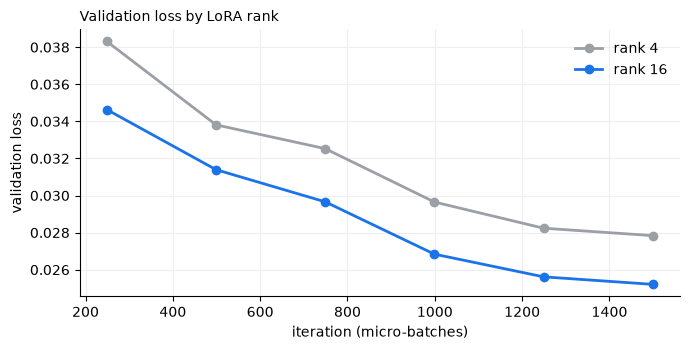

In [19]:
# Validation loss per rank (same fixed 96-example subset; iteration 0 = untrained base, 0.638 for all, not plotted)
fig, ax = plt.subplots(figsize=(7, 3.6))
colors = {"r4": "#9aa0a6", "r8": "#f29900", "r16": "#1a73e8"}
for name, tag in er.ABLATION.items():
    f = ROOT / "runs" / tag / "metrics.jsonl"
    if name == "base" or not f.exists():
        continue
    v = [json.loads(l) for l in open(f) if '"val"' in l]
    v = [x for x in v if x["iteration"] > 0]
    if v:
        ax.plot([x["iteration"] for x in v], [x["val_loss"] for x in v], marker="o", ms=6, lw=2,
                color=colors[name], label=f"rank {name[1:]}")
ax.set_xlabel("iteration (micro-batches)"); ax.set_ylabel("validation loss")
ax.grid(color="#eeeeee"); ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False)
ax.set_title("Validation loss by LoRA rank", fontsize=10, loc="left")
plt.tight_layout(); plt.show()

In [20]:
# Per-category F1 (contract level), every model side by side; the best score per category is highlighted
cats = [(k, c) for k, cs in (("trained", HEADER_CATEGORIES + CLAUSE_CATEGORIES), ("heldout", HELDOUT_CATEGORIES)) for c in cs]
pcr = pd.DataFrame({name: [abl[name][k]["contract"]["per_category"].get(c, {}).get("F1") for k, c in cats]
                    for name in er.ABLATION}, index=[c for _, c in cats]).apply(pd.to_numeric)
pcr.insert(0, "group", ["header" if c in HEADER_CATEGORIES else "clause" if c in CLAUSE_CATEGORIES else "held-out"
                        for _, c in cats])
display(pcr.style.format(precision=3, na_rep="–").highlight_max(axis=1, subset=list(er.ABLATION), color="#d2e3fc"))

,group,base,r4,r16
Document Name,header,0.532,0.882,0.897
Parties,header,0.606,0.852,0.864
Agreement Date,header,0.375,0.828,0.821
Effective Date,header,0.263,0.712,0.601
Expiration Date,clause,0.500,0.876,0.857
Renewal Term,clause,0.529,0.825,0.800
Notice Period To Terminate Renewal,clause,0.556,0.875,0.848
Governing Law,clause,0.767,0.958,0.958
Termination For Convenience,clause,0.339,0.750,0.772
Anti-Assignment,clause,0.521,0.743,0.768


## Step 12 · Save the results

In [21]:
out = ROOT / "results/eval"
(out / f"summary_{SPLIT}.json").write_text(json.dumps(res, indent=1))
(out / f"summary_{SPLIT}.md").write_text(er.to_markdown(res, SPLIT))
pc.to_csv(out / f"per_category_{SPLIT}.csv", index=False)
at.to_csv(out / f"rank_ablation_{SPLIT}.csv"); pcr.to_csv(out / f"rank_ablation_per_category_{SPLIT}.csv")
print("wrote", *(f"results/eval/{n}_{SPLIT}.{e}" for n, e in (("summary", "json"), ("summary", "md"), ("per_category", "csv"), ("rank_ablation", "csv"), ("rank_ablation_per_category", "csv"))), sep="\n  ")

wrote
  results/eval/summary_test.json
  results/eval/summary_test.md
  results/eval/per_category_test.csv
  results/eval/rank_ablation_test.csv
  results/eval/rank_ablation_per_category_test.csv


## Next steps
* **Catastrophic-forgetting check:** compare base vs adapter on a small general benchmark subset.
* **Validation-split run** (`SPLIT = "val"`) if any post-processing is changed. Never tune on test.
* Further ablations: DoRA, and 2 epochs (validation loss was still falling at the end of epoch 1).